# Using SHAP vs residual error plots

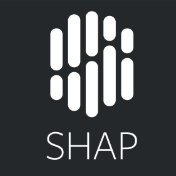

<i> 

<br>
<br>

As we know,<u>`SHAP` only looks at the model's behavior, not model performance. </u>

And that can become a significant limitation. 

<br>

<strong style="color:red;background-color:black;"> Even though our model thinks `FeatureA` is important, `FeatureA` could also be making our model worse. </strong>

So, `SHAP` can sometimes lead us in the wrong direction when optimizing datasets.

This trap is difficult to mitigate, as there is no `shap.plot` that visualizes model accuracy with Shapley values. There are also very little tools which alleviate this problem.

<br>

But there is a custom visual that you can create which allows you to combine both model's error and its Shapley values.

<br>

This notebook will show how to make a visual that answers the following:


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

* A method to visualize the predicted vs. Shapley values together with the actual row values.

* A method to find out which feature contributes to the bad decisions the most.

* A visual to find weaknesses in features to optimize (based on ERROR metrics, the source of truth,)

* Whether the mover is overall underpredicting or overpredicting.

</div>




---

## Code

<i>

We start by making a simple `XGBoost` model. 

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from xgboost import XGBRegressor
from sklearn import metrics

# Load into a single DataFrame
df = fetch_california_housing(as_frame=True).frame
df = df.rename(columns={"MedHouseVal": "target"})
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


<i> 

Then we train a very simple model and provide the metrics

In [ ]:
# X, y -- Test, train split
X = df.drop(columns=["target", "AveBedrms"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train
model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# -- METRICS RECORDING -- 
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
r_sq = metrics.r2_score(y_test, y_pred)

# -- PRINT METRICS --
print("METRICS")
print("--------------------------")
print("MAE")
print(f"{round(mae,2)} \n")
print("MSE")
print(f"{round(mse,2)} \n")
print("RMSE")
print(f"{round(rmse,2)} \n")
print('R-squared:')
print(f"{round(r_sq,2)} \n")


METRICS
--------------------------
MAE
0.3 

MSE
0.21 

RMSE
0.45 

R-squared:
0.84 



---

## <i> Visual

<i>

We're going to visualize our model performance AND model behavior at the same time.

<br><br>

Let's first start with an analogy to help you understand the visual we're about to create.

<u>Suppose a person is tried for a crime, it could go into four ways</u> -- Mapped out like so:

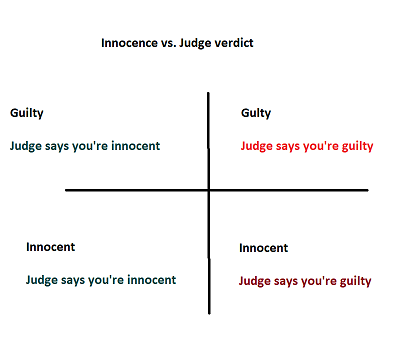


This creates a 2D visual that shows all of the possible options that could happen in this trial. 

* The accused can either be innocent or guilty.

* And the judge may render them innocent or guilty.

<br>

#### <strong style='color:teal ; background-color:black;'>True VS. Verdict. </strong>


<br>

Now, we take that same logic and expand it to shapley values and error metrics.

Instead of True vs. Verdict, we use:

#### <strong style='color:yellow ; background-color:black;'> Shapley values vs. Prediction error </strong>

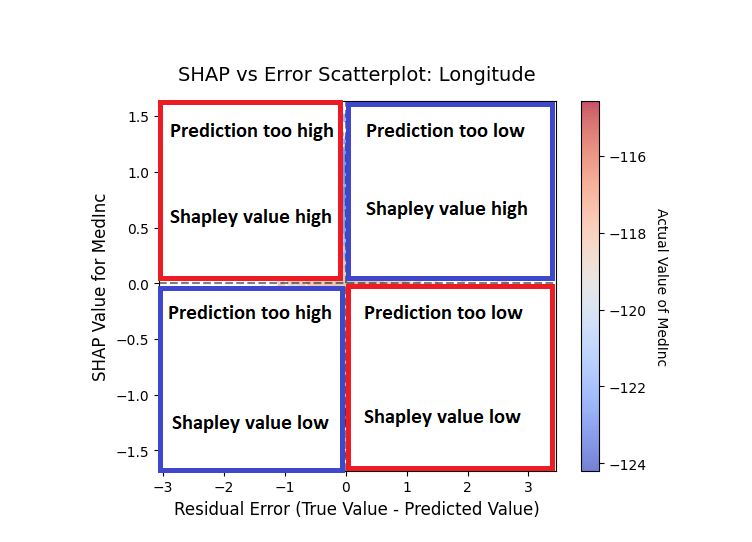


Where the X-axis is the prediction error...

And the Y-axis is the Shapley values...

And the hues/color is the ACTUAL values from the dataset.

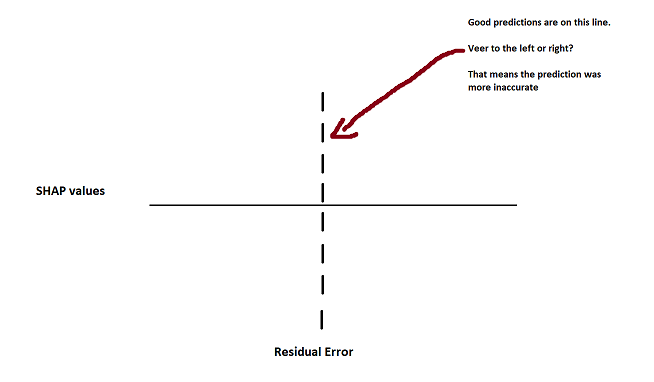

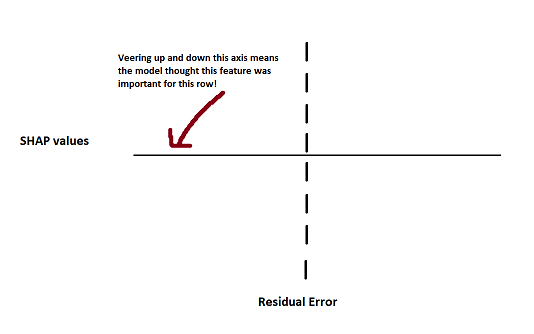

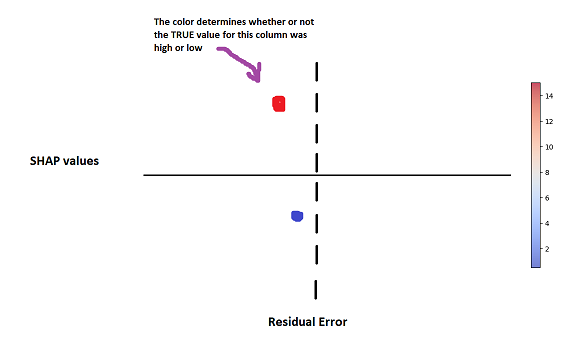

This will give you a scatterplot that lets you figure out whether or not your model overvalued or under valued each feature and you'll know how SHAP made mistakes in your model performance.

#### Getting Shapley Values, Prediction Error

In [ ]:
# Get the prediction error.
residuals = y_test - y_pred

# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

#### Creating SHAP vs Error Scatter for every feature 

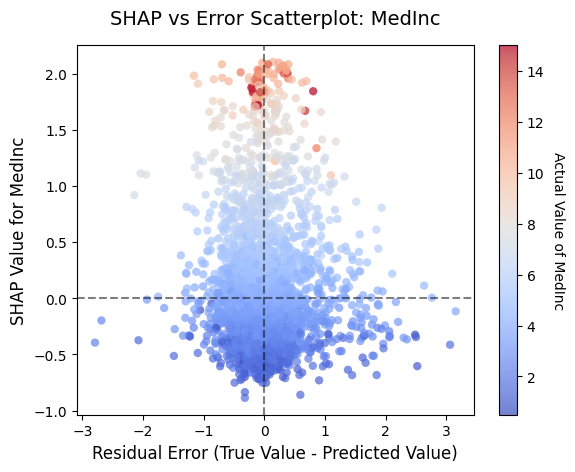

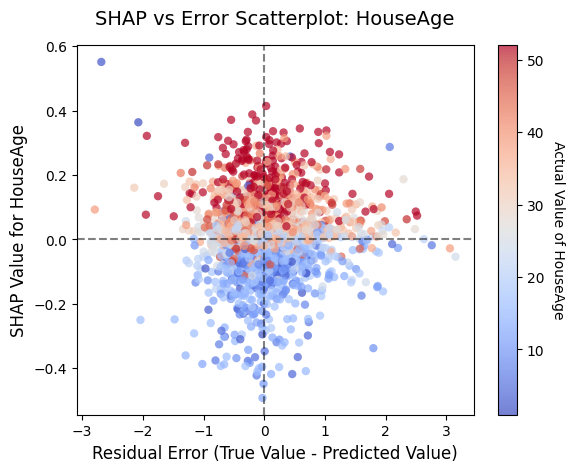

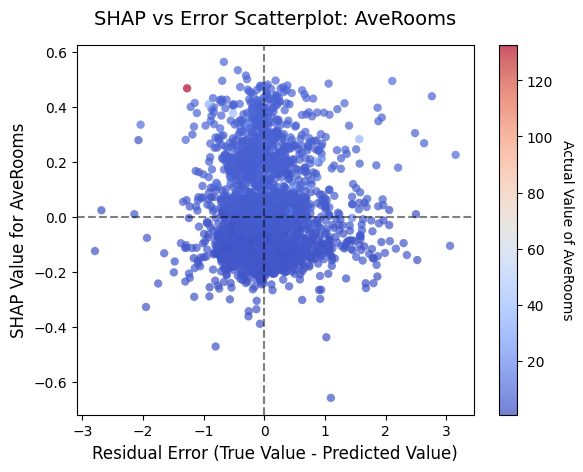

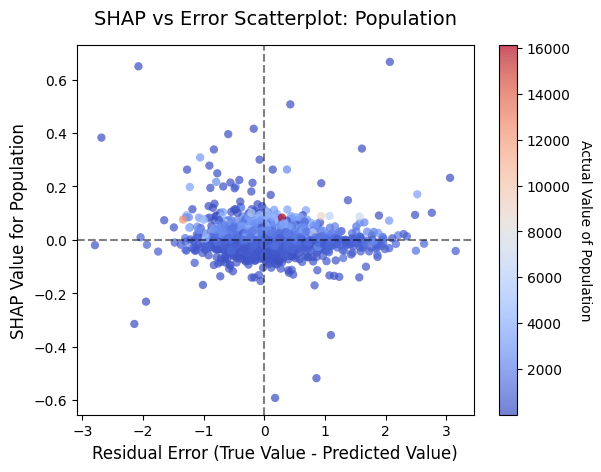

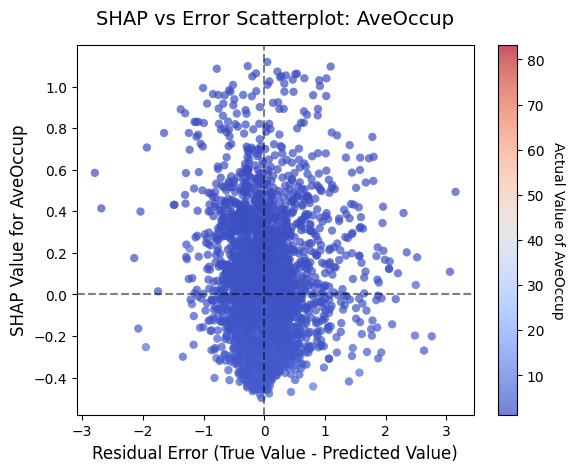

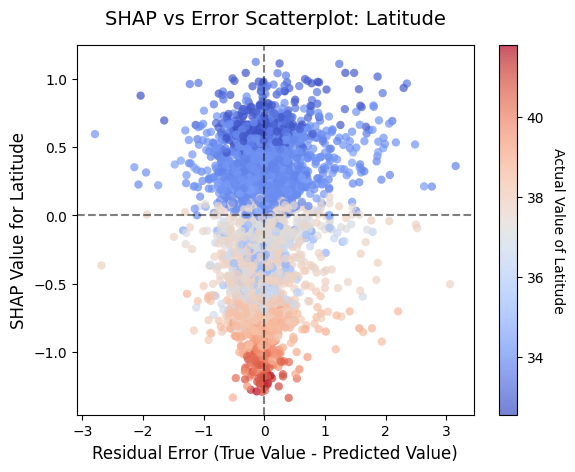

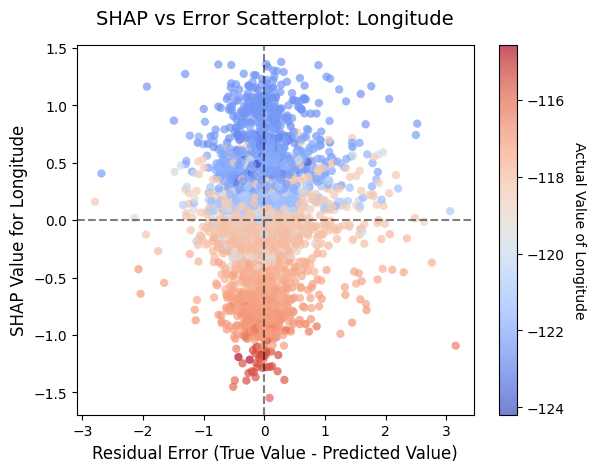

In [ ]:
columns = X.columns

for column in columns:

    # INSERT YOUR TARGET FEATURE HERE
    feature_column = column

    # Get the index of that column.
    feature_index = X_test.columns.get_loc(feature_column)

    # Get the shap values
    feat_shap_values = shap_values.values[:, feature_index]

    # Get the raw values
    feat_raw_values = X_test[feature_column].values

    # SHAP vs Error Scatterplot
    sc = plt.scatter(residuals, feat_shap_values, c=feat_raw_values, 
                    cmap='coolwarm', alpha=0.7, edgecolors='none')

    # Create lines
    plt.axhline(0, color='black', linestyle='--', alpha=0.5) 
    plt.axvline(0, color='black', linestyle='--', alpha=0.5) 

    # Labels and Styling
    plt.title(f"SHAP vs Error Scatterplot: {feature_column}", fontsize=14, pad=15)
    plt.xlabel("Residual Error (True Value - Predicted Value)", fontsize=12)
    plt.ylabel(f"SHAP Value for {feature_column}", fontsize=12)
    cbar = plt.colorbar(sc)
    cbar.set_label(f"Actual Value of {feature_column}", rotation=270, labelpad=15)
    plt.show()

# Viola, now for every feature you have a graphical output for the models behavior
# AND how much the model valued that particular row.

# This is stupendously powerful visual for figuring out what range of values
# in a feature are difficult for a model to understand. 

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>
Now let's practice interpreting these graphs and show you what you can get from them:

<br>
<br>


<br>

<br>

#### Insight 1:

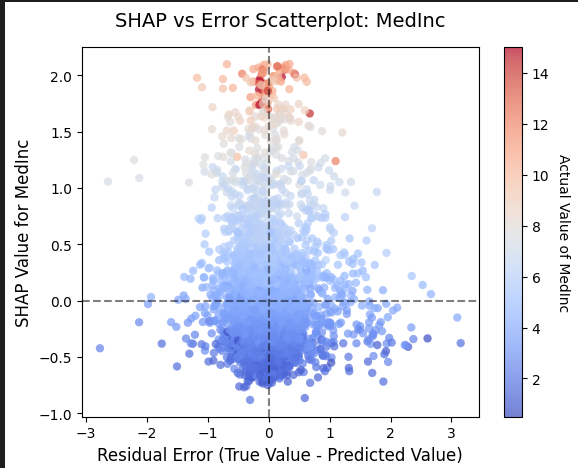

Notice how the dots at the bottom veer more to the left and right? That means the lower (blue) values are more difficult for the model to interpret. Why?

We should use data analytical tools to inspect `MedInc`. Particularly, we should check if the distribution for this feature. If it is right-skewed,

then we found our culprit and can use a transformation make it normal-like for the model and improve the metrics.



<br>
<br>

#### Insight 2:

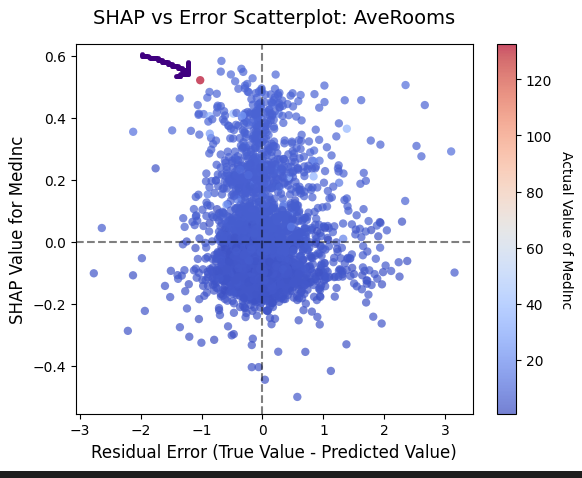

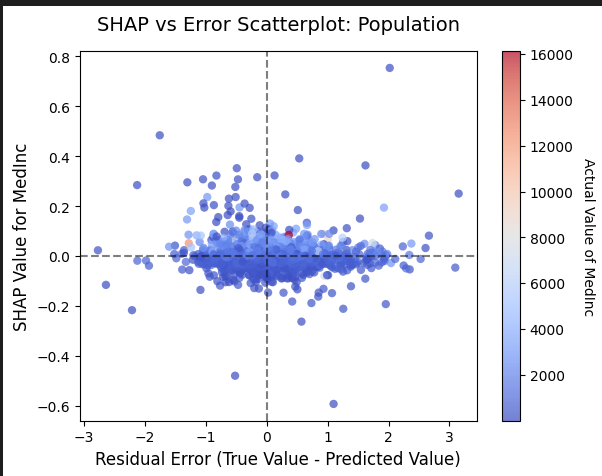

In the images above you see a value that is quite high compared to the others and it turning all the other values blue.

That's a clear outlier (red color). Therefore, the variance is high. And that probably is affecting the model.

We should consider getting rid of these outliers, transforming the column, and/or use scaling (though keep in mind, we have to keep the data real)


<br>
<br>

#### Insight 3:

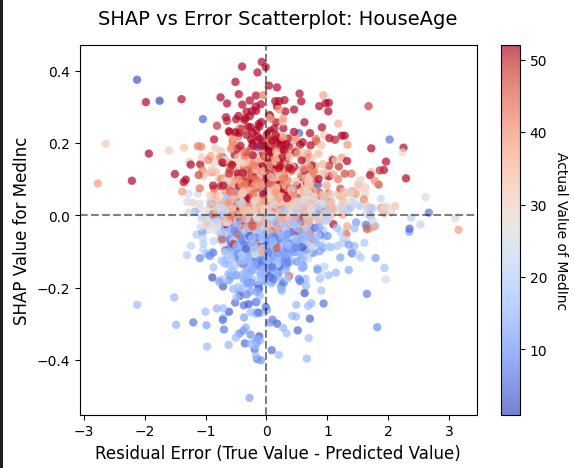

We can see a lot of overlap and widely spread cluster definitions. The color gradient shows a linear relationship between Shap values vs Actual, but there's a lot of errors.

This is likely <strong> predictive noise </strong> and a limitation of the dataset.

But it is worth investigating, because we can't be sure. Trying some interaction features, using `PCA` might be useful here.


<br>
<br>

##### <u> So, whats the insight? </u>

We need to research and look more deeply into this `HouseAge`.

Maybe another model can interpret this behavior better?

Or maybe we can introduce an interaction feature that uses `HouseAge` more effectively?




<br>
<br>





</div>

